# Module 09, Part 2: Exploration and exploitation

This notebook is the runnable companion to Part 2 of the Module 09 learning content. It checks, with code:

1. That a purely greedy agent can lock onto a poor action in a multi-armed bandit, and how often.
2. How optimism, random exploration and an exploration bonus change the total regret, on 200 different bandit problems.
3. What the exploration rate $\epsilon$ costs when it is too small and when it is too large.
4. That the same lesson holds in a sequential problem: tabular Q-learning on the grid from Part 1, with and without exploration.

The bandit has 10 arms. Each arm has a fixed true mean drawn from a standard normal, and each pull returns that mean plus standard normal noise. **Regret** is the best arm's mean minus the mean of the arm that was pulled, added up over time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np

ACTIONS = ["up", "right", "down", "left"]
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]


class GridMDP:
    """Rows 0 to 3, columns 0 to 3. The goal (+1) is the top-right corner, the pit (-1) is the cell below it.
    Both are terminal. A wall cell sits at (1, 1). Every other step costs `step_cost`.
    With probability `slip` the agent moves at a right angle to the chosen direction (half each way)."""
    def __init__(self, slip=0.2, step_cost=0.0, gamma=0.9):
        self.n_rows = self.n_cols = 4
        self.goal, self.pit, self.wall = (0, 3), (1, 3), (1, 1)
        self.slip, self.step_cost, self.gamma = slip, step_cost, gamma
        self.cells = [(r, c) for r in range(4) for c in range(4) if (r, c) != self.wall]
        self.idx = {cell: i for i, cell in enumerate(self.cells)}
        self.nS, self.nA = len(self.cells), 4
        self.terminal = np.array([c in (self.goal, self.pit) for c in self.cells])
        self.P = np.zeros((self.nS, self.nA, self.nS))
        self.R = np.zeros((self.nS, self.nA))
        for cell in self.cells:
            s = self.idx[cell]
            if self.terminal[s]:
                self.P[s, :, s] = 1.0        # absorbing, no further reward
                continue
            for a in range(self.nA):
                for a2, pr in ((a, 1 - slip), ((a + 1) % 4, slip / 2), ((a - 1) % 4, slip / 2)):
                    nxt = self._move(cell, a2)
                    self.P[s, a, self.idx[nxt]] += pr
                    reward = 1.0 if nxt == self.goal else -1.0 if nxt == self.pit else step_cost
                    self.R[s, a] += pr * reward

    def _move(self, cell, a):
        r, c = cell[0] + MOVES[a][0], cell[1] + MOVES[a][1]
        if not (0 <= r < 4 and 0 <= c < 4) or (r, c) == self.wall:
            return cell
        return (r, c)

    def sample_step(self, s, a, rng):
        s2 = rng.choice(self.nS, p=self.P[s, a])
        return s2, self.R[s, a]


def evaluate_policy(mdp, pi):
    """Solve the Bellman expectation equations v = r_pi + gamma P_pi v exactly. pi has shape (nS, nA)."""
    P_pi = np.einsum("sa,sat->st", pi, mdp.P)
    r_pi = np.einsum("sa,sa->s", pi, mdp.R)
    return np.linalg.solve(np.eye(mdp.nS) - mdp.gamma * P_pi, r_pi)


def q_from_v(mdp, v):
    return mdp.R + mdp.gamma * mdp.P @ v


def value_iteration(mdp, tol=1e-10, max_iter=10000):
    v = np.zeros(mdp.nS)
    for k in range(1, max_iter + 1):
        v_new = q_from_v(mdp, v).max(1)
        done = np.abs(v_new - v).max() < tol
        v = v_new
        if done:
            break
    return v, k


def greedy_policy(q):
    pi = np.zeros_like(q)
    pi[np.arange(len(q)), q.argmax(1)] = 1.0
    return pi


def discounted_return(rewards, gamma):
    g = 0.0
    for r in reversed(rewards):
        g = r + gamma * g
    return g


def rollout_return(mdp, pi, s0, rng, max_steps=200):
    s, rewards = s0, []
    for _ in range(max_steps):
        if mdp.terminal[s]:
            break
        a = rng.choice(mdp.nA, p=pi[s])
        s, r = mdp.sample_step(s, a, rng)
        rewards.append(r)
    return discounted_return(rewards, mdp.gamma), len(rewards)


def q_learning(mdp, steps=20000, eps=0.1, alpha=0.1, seed=0, start=None, max_ep_len=100, optimistic=0.0):
    """Tabular Q-learning with an epsilon-greedy behaviour policy. Returns the Q table and how many
    episodes reached the goal. Every episode starts in `start` (default: the bottom-left corner)."""
    rng = np.random.default_rng(seed)
    start = mdp.idx[(3, 0)] if start is None else start
    Q = np.full((mdp.nS, mdp.nA), optimistic)
    Q[mdp.terminal] = 0.0
    s, ep_len, goals = start, 0, 0
    goal_state = mdp.idx[mdp.goal]
    for _ in range(steps):
        a = int(rng.integers(mdp.nA)) if rng.random() < eps else int(np.argmax(Q[s] + 1e-9 * rng.random(mdp.nA)))
        s2, r = mdp.sample_step(s, a, rng)
        Q[s, a] += alpha * (r + mdp.gamma * Q[s2].max() - Q[s, a])
        ep_len += 1
        if mdp.terminal[s2] or ep_len >= max_ep_len:
            goals += int(s2 == goal_state)
            s, ep_len = start, 0
        else:
            s = s2
    return Q, goals


def softmax_policy(theta):
    import torch
    return torch.softmax(theta, dim=1)


def exact_objective(mdp, theta, s0):
    """J(theta) = v_pi(s0) for a softmax policy with logits theta (nS by nA), computed exactly and differentiably."""
    import torch
    pi = torch.softmax(theta, dim=1)
    P = torch.as_tensor(mdp.P, dtype=torch.float64); R = torch.as_tensor(mdp.R, dtype=torch.float64)
    P_pi = torch.einsum("sa,sat->st", pi, P); r_pi = (pi * R).sum(1)
    v = torch.linalg.solve(torch.eye(mdp.nS, dtype=torch.float64) - mdp.gamma * P_pi, r_pi)
    return v[s0]


def reinforce_gradient_estimate(mdp, theta, s0, n_episodes, rng, baseline=False, max_steps=100):
    """Monte Carlo policy-gradient estimate: average over episodes of sum_t gamma^t grad log pi(a_t|s_t) (G_t - b).
    With baseline=True, b is the exact state value v_pi(s_t), which depends on the state and not on the action."""
    pi = np.exp(theta - theta.max(1, keepdims=True)); pi /= pi.sum(1, keepdims=True)
    v = evaluate_policy(mdp, pi) if baseline else np.zeros(mdp.nS)
    grads = np.zeros((n_episodes,) + theta.shape)
    for e in range(n_episodes):
        s, traj = s0, []
        for _ in range(max_steps):
            if mdp.terminal[s]:
                break
            a = rng.choice(mdp.nA, p=pi[s]); s2, r = mdp.sample_step(s, a, rng)
            traj.append((s, a, r)); s = s2
        G = 0.0
        for t in reversed(range(len(traj))):
            s_t, a_t, r_t = traj[t]
            G = r_t + mdp.gamma * G
            g = -pi[s_t].copy(); g[a_t] += 1.0          # gradient of log softmax with respect to the logits
            grads[e, s_t] += mdp.gamma ** t * g * (G - v[s_t])
    return grads

In [3]:
import numpy as np


class Bandit:
    """k arms with Gaussian rewards. The true means are drawn once, from a standard normal; each pull adds unit noise."""
    def __init__(self, k=10, seed=0):
        rng = np.random.default_rng(seed)
        self.k = k
        self.means = rng.normal(0, 1, k)
        self.best = self.means.max()
        self.rng = np.random.default_rng(seed + 10_000)

    def pull(self, a):
        return self.means[a] + self.rng.normal()


def run_bandit(bandit, strategy, steps=1000, eps=0.1, c=2.0, optimistic=0.0, tau=0.2):
    """Returns the per-step regret (best mean minus the mean of the arm chosen) and the pulls of each arm.
    strategy: 'greedy' (use `optimistic` as the starting estimate), 'epsilon', 'ucb' or 'softmax'."""
    k = bandit.k
    n = np.zeros(k)
    est = np.full(k, optimistic if strategy == "greedy" else 0.0)
    regret = np.zeros(steps)
    rng = np.random.default_rng(1)
    for t in range(steps):
        if strategy == "greedy":
            a = int(np.argmax(est + 1e-9 * rng.random(k)))
        elif strategy == "epsilon":
            a = int(rng.integers(k)) if rng.random() < eps else int(np.argmax(est))
        elif strategy == "ucb":
            a = t if t < k else int(np.argmax(est + c * np.sqrt(np.log(t + 1) / np.maximum(n, 1))))
        elif strategy == "softmax":
            p = np.exp((est - est.max()) / tau); p /= p.sum()
            a = int(rng.choice(k, p=p))
        else:
            raise ValueError(strategy)
        r = bandit.pull(a)
        n[a] += 1
        est[a] += (r - est[a]) / n[a]
        regret[t] = bandit.best - bandit.means[a]
    return regret, n

## 1. Greedy can get stuck

A greedy agent always pulls the arm with the best estimate so far. If an early pull of a good arm comes out low, the agent may never pull it again and never learn it was good. We run 200 different bandit problems of 1,000 pulls each with five strategies and record three things:
the total regret, the share of pulls that went to the best arm, and the share of problems in which the arm pulled most often was not the best one.

In [4]:
strategies = {
    "greedy (start at 0)":       ("greedy",  dict()),
    "greedy, optimistic start 5": ("greedy",  dict(optimistic=5.0)),
    "epsilon-greedy, eps 0.01":  ("epsilon", dict(eps=0.01)),
    "epsilon-greedy, eps 0.1":   ("epsilon", dict(eps=0.1)),
    "epsilon-greedy, eps 0.3":   ("epsilon", dict(eps=0.3)),
    "UCB, c = 2":                ("ucb",     dict(c=2.0)),
    "softmax, tau = 0.2":        ("softmax", dict(tau=0.2)),
}
N, STEPS = 200, 1000
curves, rows = {}, []
for name, (st, kw) in strategies.items():
    reg = np.zeros((N, STEPS)); best_share = np.zeros(N); wrong = np.zeros(N)
    for seed in range(N):
        b = Bandit(10, seed)
        r, n = run_bandit(b, st, STEPS, **kw)
        reg[seed] = r
        best_share[seed] = n[b.means.argmax()] / STEPS
        wrong[seed] = n.argmax() != b.means.argmax()
    curves[name] = reg.cumsum(1).mean(0)
    rows.append((name, reg.sum(1).mean(), reg.sum(1).std() / np.sqrt(N), best_share.mean(), wrong.mean()))
print(f"{'strategy':28s} {'total regret':>14s}  {'pulls of best arm':>18s}  {'problems where most-pulled arm is not best':>44s}")
for name, tot, se, bs, wr in rows:
    print(f"{name:28s} {tot:8.1f} +/- {se:4.1f}  {bs:17.1%}  {wr:43.1%}")

strategy                       total regret   pulls of best arm    problems where most-pulled arm is not best
greedy (start at 0)             547.6 +/- 39.8              30.8%                                        69.0%
greedy, optimistic start 5      131.2 +/- 17.2              70.7%                                        28.5%
epsilon-greedy, eps 0.01        312.7 +/- 22.4              49.3%                                        51.5%
epsilon-greedy, eps 0.1         224.9 +/-  9.6              70.6%                                        18.0%
epsilon-greedy, eps 0.3         469.9 +/- 10.1              61.7%                                        14.5%
UCB, c = 2                      149.9 +/-  2.1              74.6%                                         6.0%
softmax, tau = 0.2              166.9 +/- 16.4              66.3%                                        23.0%


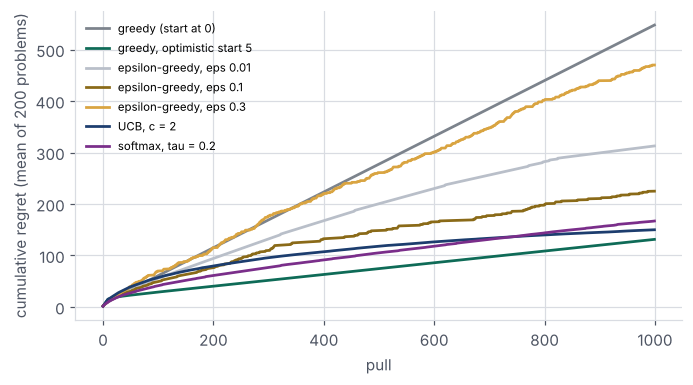

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
cols = [MUTED, GREEN, "#b9bfc9", AMBER, "#d9a441", NAVY, KEY]
for (name, c), col in zip(curves.items(), cols):
    ax.plot(c, label=name, color=col, lw=1.8)
ax.set_xlabel("pull"); ax.set_ylabel("cumulative regret (mean of 200 problems)"); ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.show()

Plain greedy collects regret at a constant rate for the whole run: in a large share of problems it settles on an arm that is not the best and stays there. Starting the estimates optimistically, at 5 when real means are near 0, forces the agent to try every arm because each pull of an arm brings its estimate down, and it removes most of the regret.
An exploration bonus (UCB) and softmax selection also work. Random exploration with $\epsilon$ is the simplest method and it keeps spending pulls on arms it already knows are worse, so its regret grows steadily even late in the run.

## 2. How much to explore

For $\epsilon$-greedy, too little exploration repeats the greedy failure more slowly and too much wastes pulls for ever. We sweep $\epsilon$ and split the regret into two parts: the average regret per pull over the first 100 pulls (learning), and over the last 100 (what is lost once learning is done).

In [6]:
print(" eps    total regret   regret per pull, pulls 1-100   regret per pull, pulls 901-1000")
for eps in (0.0, 0.01, 0.03, 0.1, 0.3, 0.6):
    reg = np.array([run_bandit(Bandit(10, s), "epsilon", STEPS, eps=eps)[0] for s in range(N)])
    print(f"{eps:5.2f}   {reg.sum(1).mean():10.1f}   {reg[:, :100].mean():26.3f}   {reg[:, -100:].mean():30.3f}")

 eps    total regret   regret per pull, pulls 1-100   regret per pull, pulls 901-1000


 0.00        476.4                        0.559                            0.466


 0.01        312.7                        0.553                            0.136


 0.03        220.4                        0.502                            0.097


 0.10        224.9                        0.491                            0.143


 0.30        469.9                        0.697                            0.304


 0.60        897.5                        0.972                            0.838


The last column is the cost of exploring after learning is done: it falls from 0.47 with no exploration to about 0.10 at $\epsilon = 0.03$, where the agent has found the best arm in most problems, and then rises roughly in proportion to $\epsilon$, because every random pull of a worse arm costs the gap between that arm and the best.
The first-100 column improves slightly as $\epsilon$ goes from 0 to 0.1 and then gets worse, since at high $\epsilon$ most early pulls are random too. The best total regret sits between the extremes, at 0.03 to 0.1. A fixed $\epsilon$ cannot be right for both phases,
which is why practical agents start with a high $\epsilon$ and reduce it over time, as the DQN in Part 3 does.

## 3. The same problem in a sequential task

In a grid, exploration has a second job: reaching the states from which the reward can be found at all. We run tabular Q-learning, which updates $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$, from the bottom-left corner of the grid in Part 1 for 50,000 steps,
with five seeds for each setting. We score each learned Q table by the exact value of the start cell under its greedy policy (the best possible is 0.4729).

In [7]:
mdp = GridMDP(slip=0.2, gamma=0.9)
start = mdp.idx[(3, 0)]
v_star, _ = value_iteration(mdp)
print(f"optimal value of the start cell: {v_star[start]:.4f}\n")
print("setting                         value of the greedy policy at the start (5 seeds)     mean   episodes that reached the goal")
for label, kw in [("eps 0 (no exploration)", dict(eps=0.0)), ("eps 0.02", dict(eps=0.02)), ("eps 0.1", dict(eps=0.1)),
                  ("eps 0.3", dict(eps=0.3)), ("eps 0, optimistic start 1", dict(eps=0.0, optimistic=1.0))]:
    vals, goals = [], []
    for seed in range(5):
        Q, g = q_learning(mdp, steps=50000, seed=seed, **kw)
        vals.append(evaluate_policy(mdp, greedy_policy(Q))[start]); goals.append(g)
    print(f"{label:30s}  {np.round(vals, 3)}   {np.mean(vals):.3f}   {np.mean(goals):8.0f}")

optimal value of the start cell: 0.4729

setting                         value of the greedy policy at the start (5 seeds)     mean   episodes that reached the goal


eps 0 (no exploration)          [0.119 0.032 0.035 0.039 0.244]   0.094       1016


eps 0.02                        [0.472 0.462 0.353 0.36  0.471]   0.424       5065


eps 0.1                         [0.363 0.36  0.472 0.472 0.473]   0.428       4911


eps 0.3                         [0.471 0.473 0.472 0.471 0.243]   0.426       3845


eps 0, optimistic start 1       [0.473 0.47  0.471 0.473 0.471]   0.472       5851


Without any exploration no seed comes close to the optimum: the best reaches 0.244 and the mean is 0.094, because the greedy agent keeps repeating whatever its first tie-breaks happened to select. With an exploration rate of 0.02, 0.1 or 0.3 most seeds reach the optimum or within 0.01 of it, and one or two seeds in each setting stop short.
The optimistic start reaches the goal reliably, with all five seeds within 0.003 of the optimum, without a single random action. The table also shows something to carry into the next part: even with a good exploration rate, the answer after a fixed budget is not exactly optimal, and seeds disagree. Reinforcement-learning results are always reported over several seeds for this reason.

**Try it.** Change the slip probability and see whether the best $\epsilon$ moves. Then add a decay to $\epsilon$ and compare with a fixed value.